In [1]:

!pip -q install seaborn scikit-learn

import os
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)
from sklearn.utils.class_weight import compute_class_weight

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow version:", tf.__version__)
print("GPU available:", len(tf.config.list_physical_devices("GPU")) > 0)


TensorFlow version: 2.21.0
GPU available: False


In [5]:

from google.colab import files
import zipfile
import os
import glob
import pandas as pd

# Upload your ZIP file
uploaded = files.upload()

zip_file = next(
    name for name in uploaded if name.lower().endswith(".zip")
)

# Extract the folder
with zipfile.ZipFile(zip_file, "r") as z:
    z.extractall("/content/fake_news_data")

# Find both CSV files
csv_files = glob.glob(
    "/content/fake_news_data/**/*.csv",
    recursive=True
)

print("CSV files found:")
for file in csv_files:
    print(file)


Saving archive (4).zip to archive (4).zip
CSV files found:
/content/fake_news_data/true.csv
/content/fake_news_data/fake.csv


In [6]:

fake_file = next(
    (f for f in csv_files if "fake" in os.path.basename(f).lower()),
    None
)

real_file = next(
    (f for f in csv_files if
     "true" in os.path.basename(f).lower()
     or "real" in os.path.basename(f).lower()),
    None
)

if fake_file is None or real_file is None:
    raise ValueError(
        "ZIP must contain fake.csv and true.csv (or real.csv)."
    )

fake_df = pd.read_csv(fake_file, encoding="utf-8", on_bad_lines="skip")
real_df = pd.read_csv(real_file, encoding="utf-8", on_bad_lines="skip")

fake_df["label"] = 0
real_df["label"] = 1

df = pd.concat([fake_df, real_df], ignore_index=True)

print("Fake news articles:", len(fake_df))
print("Real news articles:", len(real_df))
print("Combined dataset shape:", df.shape)


Fake news articles: 23481
Real news articles: 21417
Combined dataset shape: (44898, 5)


In [7]:
print(df["label"].value_counts())

label
0    23481
1    21417
Name: count, dtype: int64


Selected articles: 2000

Label counts:
label
0    1000
1    1000
Name: count, dtype: int64

0 = Fake News, 1 = Real News


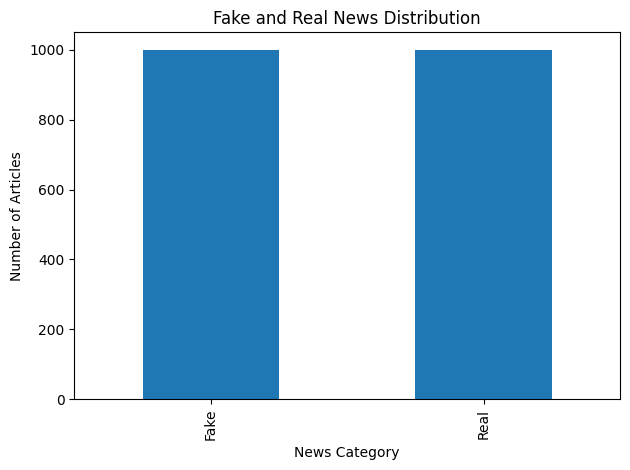

In [8]:

# Identify available title and article columns
title_col = next(
    (c for c in ["title", "headline"] if c in df.columns), None
)
text_col = next(
    (c for c in ["text", "article", "content", "news", "body"]
     if c in df.columns), None
)

if title_col is None and text_col is None:
    raise ValueError("No title or article text column was found.")

# Combine headline and body
parts = []

if title_col:
    parts.append(df[title_col].fillna("").astype(str))

if text_col and text_col != title_col:
    parts.append(df[text_col].fillna("").astype(str))

df["news_text"] = parts[0]

for part in parts[1:]:
    df["news_text"] = df["news_text"] + " " + part

# Clean text
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"http\S+|www\S+", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

df["news_text"] = df["news_text"].apply(clean_text)

# Remove empty and duplicate articles
df = df[df["news_text"].str.len() > 0]
df = df.drop_duplicates(subset=["news_text"]).reset_index(drop=True)

# Select up to 1000 articles from each class
fake_df = df[df["label"] == 0]
real_df = df[df["label"] == 1]

if len(fake_df) < 2 or len(real_df) < 2:
    raise ValueError("Both datasets must contain at least two valid articles.")

n = min(1000, len(fake_df), len(real_df))

df_small = pd.concat([
    fake_df.sample(n=n, random_state=SEED),
    real_df.sample(n=n, random_state=SEED)
], ignore_index=True)

df_small = df_small.sample(
    frac=1, random_state=SEED
).reset_index(drop=True)

print("Selected articles:", len(df_small))
print("\nLabel counts:")
print(df_small["label"].value_counts().sort_index())
print("\n0 = Fake News, 1 = Real News")

# Plot class distribution
df_small["label"].map({0: "Fake", 1: "Real"}).value_counts().reindex(
    ["Fake", "Real"]
).plot(kind="bar")

plt.title("Fake and Real News Distribution")
plt.xlabel("News Category")
plt.ylabel("Number of Articles")
plt.tight_layout()
plt.show()


In [9]:

X = df_small["news_text"].values
y = df_small["label"].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

MAX_WORDS = 10000
MAX_LEN = 200

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

X_train_pad = pad_sequences(
    X_train_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq, maxlen=MAX_LEN,
    padding="post", truncating="post"
)

print("Training shape:", X_train_pad.shape)
print("Testing shape:", X_test_pad.shape)
print("Training label counts:", np.unique(y_train, return_counts=True))
print("Testing label counts:", np.unique(y_test, return_counts=True))


Training shape: (1600, 200)
Testing shape: (400, 200)
Training label counts: (array([0, 1]), array([800, 800]))
Testing label counts: (array([0, 1]), array([200, 200]))


In [10]:

model = Sequential([
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.build(input_shape=(None, MAX_LEN))

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 675,137 (2.58 MB)

 Trainable params: 675,137 (2.58 MB)

 Non-trainable params: 0 (0.00 B)

In [11]:

classes = np.unique(y_train)

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    epochs=8,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights,
    callbacks=[early_stop],
    verbose=1
)



Epoch 1/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 135ms/step - accuracy: 0.5984 - loss: 0.6852 - val_accuracy: 0.7688 - val_loss: 0.6397
Epoch 2/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 112ms/step - accuracy: 0.7984 - loss: 0.5044 - val_accuracy: 0.8594 - val_loss: 0.4400
Epoch 3/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 149ms/step - accuracy: 0.8672 - loss: 0.3884 - val_accuracy: 0.8906 - val_loss: 0.3363
Epoch 4/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 133ms/step - accuracy: 0.9195 - loss: 0.2663 - val_accuracy: 0.8250 - val_loss: 0.4121
Epoch 5/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 126ms/step - accuracy: 0.9680 - loss: 0.1327 - val_accuracy: 0.9250 - val_loss: 0.2660
Epoch 6/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 5s 135ms/step - accuracy: 0.9766 - loss: 0.1006 - val_accuracy: 0.9406 - val_loss: 0.2572
Epoch 7/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 4s 112ms/step - accuracy: 0.9797 - loss: 0.0893 - val_accuracy: 0.9312 - val_loss: 0.2810
Epoch 8/8
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 149ms/step - accuracy: 0.9891 - loss: 0.0500 - val_accuracy: 0.9312 - v

In [12]:

y_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("EVALUATION RESULTS")
print("------------------")
print(f"Accuracy : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred, zero_division=0):.4f}")
print(f"Recall   : {recall_score(y_test, y_pred, zero_division=0):.4f}")
print(f"F1-score : {f1_score(y_test, y_pred, zero_division=0):.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fake News", "Real News"],
    zero_division=0
))

print("\nPredicted label counts:")
print(pd.Series(y_pred).value_counts().sort_index())


EVALUATION RESULTS
------------------
Accuracy : 0.9525
Precision: 0.9372
Recall   : 0.9700
F1-score : 0.9533

Classification Report:
              precision    recall  f1-score   support

   Fake News       0.97      0.94      0.95       200
   Real News       0.94      0.97      0.95       200

    accuracy                           0.95       400
   macro avg       0.95      0.95      0.95       400
weighted avg       0.95      0.95      0.95       400


Predicted label counts:
0    193
1    207
Name: count, dtype: int64


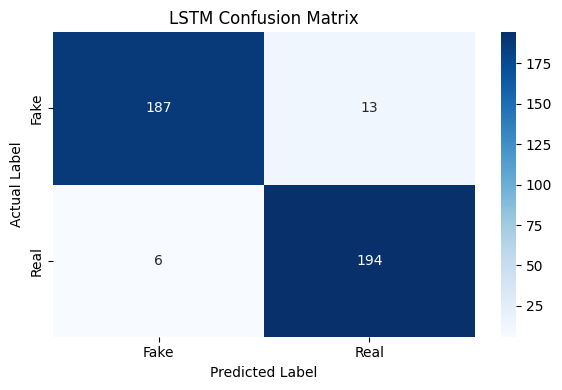

In [13]:

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 4))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Fake", "Real"],
    yticklabels=["Fake", "Real"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("LSTM Confusion Matrix")
plt.tight_layout()
plt.show()


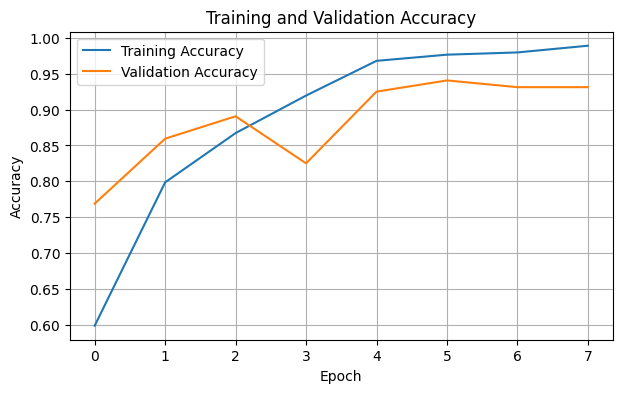

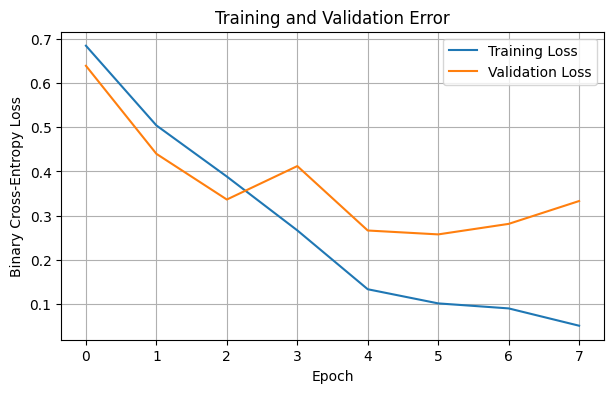

In [14]:

plt.figure(figsize=(7, 4))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training and Validation Error")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()


In [15]:

def predict_news(article):
    cleaned = clean_text(article)

    sequence = tokenizer.texts_to_sequences([cleaned])
    padded = pad_sequences(
        sequence,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

    prob_real = float(model.predict(padded, verbose=0)[0][0])

    prediction = "REAL NEWS" if prob_real >= 0.5 else "FAKE NEWS"

    print("\nArticle:", article)
    print("Prediction:", prediction)
    print(f"Fake probability: {(1 - prob_real):.2%}")
    print(f"Real probability: {prob_real:.2%}")

    return prob_real


fake_article = """
A viral online post claims every citizen will receive
one million rupees tomorrow without an official announcement.
"""

real_article = """
The national weather department published a rainfall forecast
and advised residents to follow official local weather updates.
"""

p_fake = predict_news(fake_article)
p_real = predict_news(real_article)



Article: 
A viral online post claims every citizen will receive
one million rupees tomorrow without an official announcement.

Prediction: REAL NEWS
Fake probability: 21.08%
Real probability: 78.92%

Article: 
The national weather department published a rainfall forecast
and advised residents to follow official local weather updates.

Prediction: REAL NEWS
Fake probability: 0.61%
Real probability: 99.39%


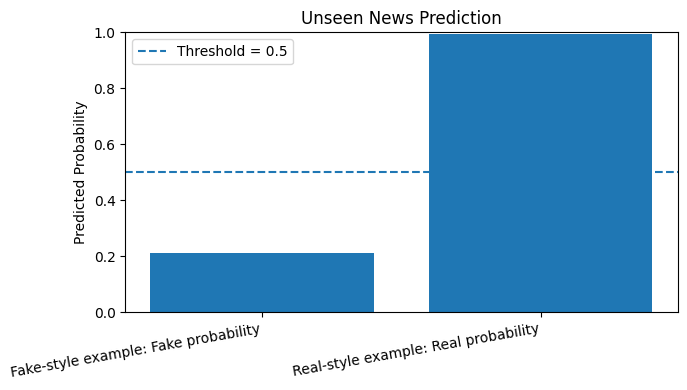

In [16]:

plt.figure(figsize=(7, 4))

labels = ["Fake-style example: Fake probability",
          "Real-style example: Real probability"]

values = [1 - p_fake, p_real]

plt.bar(labels, values)
plt.axhline(0.5, linestyle="--", label="Threshold = 0.5")
plt.ylim(0, 1)
plt.ylabel("Predicted Probability")
plt.title("Unseen News Prediction")
plt.xticks(rotation=10, ha="right")
plt.legend()
plt.tight_layout()
plt.show()


In [17]:

article = input("Enter a news article: ")
predict_news(article)


Enter a news article: the year is 2027

Article: the year is 2027
Prediction: FAKE NEWS
Fake probability: 59.18%
Real probability: 40.82%


0.4082011878490448

In [19]:

article = input("Enter a news article: ")
predict_news(article)


Enter a news article: India experienced below-average rainfall during September 2026, increasing concerns following a weak monsoon season and the strengthening El Nino weather pattern. Insufficient rainfall can affect the growth of rice, cotton, corn and soybeans. Lower crop production could affect farmers incomes, food supplies and agricultural prices. Rainfall during the monsoon season is important for farming and maintaining soil moisture. """

Article: India experienced below-average rainfall during September 2026, increasing concerns following a weak monsoon season and the strengthening El Nino weather pattern. Insufficient rainfall can affect the growth of rice, cotton, corn and soybeans. Lower crop production could affect farmers incomes, food supplies and agricultural prices. Rainfall during the monsoon season is important for farming and maintaining soil moisture. """
Prediction: REAL NEWS
Fake probability: 0.62%
Real probability: 99.38%


0.9938290119171143